# Pecan Street, Austin Data preprocessing 

The dataset is acquired form https://www.pecanstreet.org/dataport/. 

**Assumptions:** Consumer homes without any PV readings are assigned zero PV. Whole-home demand is calculated as grid import plus PV, assuming no storage/other generation. 


## Configuration

In [27]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pandas.tseries.holiday import USFederalHolidayCalendar

DATA_DIR = Path.cwd().parents[1]/'data'/'raw'
OUTPUT_DIR = Path.cwd().parents[1] / 'data'/'processed'
INPUT_FILE = DATA_DIR / '15minute_data_austin.csv'
METADATA_FILE = DATA_DIR / 'metadata.csv'


# Read the Data Files. 

In [28]:
data = pd.read_csv(INPUT_FILE)
data.columns

Index(['dataid', 'local_15min', 'air1', 'air2', 'air3', 'airwindowunit1',
       'aquarium1', 'bathroom1', 'bathroom2', 'bedroom1', 'bedroom2',
       'bedroom3', 'bedroom4', 'bedroom5', 'battery1', 'car1', 'car2',
       'circpump1', 'clotheswasher1', 'clotheswasher_dryg1', 'diningroom1',
       'diningroom2', 'dishwasher1', 'disposal1', 'drye1', 'dryg1', 'freezer1',
       'furnace1', 'furnace2', 'garage1', 'garage2', 'grid', 'heater1',
       'heater2', 'heater3', 'housefan1', 'icemaker1', 'jacuzzi1', 'kitchen1',
       'kitchen2', 'kitchenapp1', 'kitchenapp2', 'lights_plugs1',
       'lights_plugs2', 'lights_plugs3', 'lights_plugs4', 'lights_plugs5',
       'lights_plugs6', 'livingroom1', 'livingroom2', 'microwave1', 'office1',
       'outsidelights_plugs1', 'outsidelights_plugs2', 'oven1', 'oven2',
       'pool1', 'pool2', 'poollight1', 'poolpump1', 'pump1', 'range1',
       'refrigerator1', 'refrigerator2', 'security1', 'sewerpump1', 'shed1',
       'solar', 'solar2', 'sprinkler1

In [29]:
metadata = pd.read_csv(METADATA_FILE)
austin_metadata = metadata[metadata['city']=='Austin']


In [30]:
SOURCE_POWER_UNIT = 'kW'

## Find Prosumers and Consumers.

In [31]:
austin_metadata['dataid'] = pd.to_numeric(austin_metadata['dataid'], errors='coerce')
data['dataid'] = pd.to_numeric(data['dataid'], errors='coerce')
PROSUMERS = []
CONSUMERS = []
customer_type = {}
for id in data['dataid'].unique():
    if id not in austin_metadata['dataid'].values:
        print(f"Data ID {id} is not present in the metadata.")
    else:
        row = austin_metadata[austin_metadata['dataid'] == id].iloc[0]
        if row['pv'] == 'yes':
            customer_type[id] = 'prosumer'   
            PROSUMERS.append(id.item())       
        else:
            customer_type[id] = 'consumer'
            CONSUMERS.append(id.item())

PARTICIPANTS =  PROSUMERS + CONSUMERS

### Analyzing the Solar Data in columns 'solar' and 'solar2:

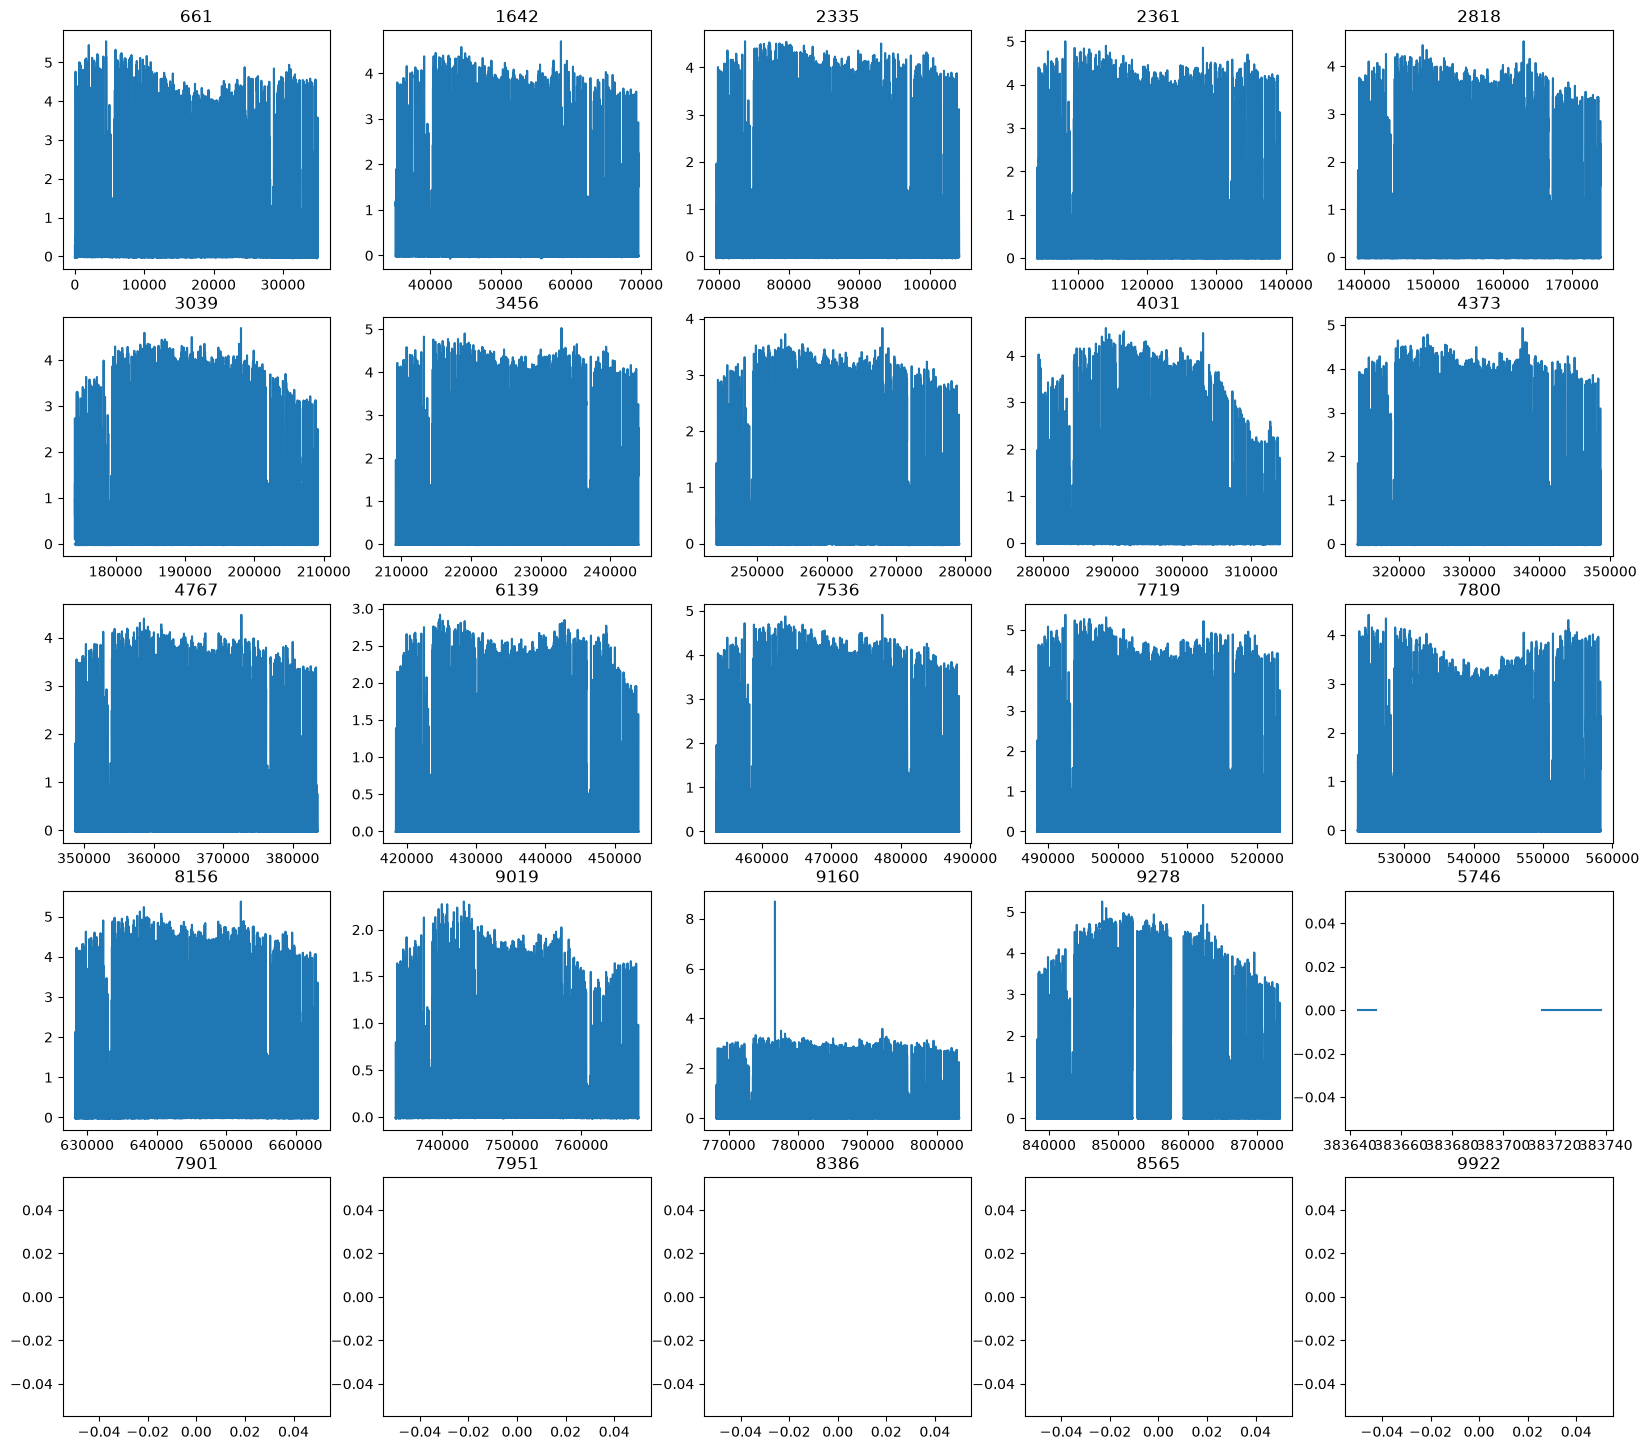

In [32]:
fig, axes = plt.subplots(nrows=5, ncols=5, figsize=(20,18))
axes = axes.flatten()
for i, ax in enumerate(axes):
    ax.plot(data[data['dataid']==PARTICIPANTS[i]].solar)
    ax.set_title(str(PARTICIPANTS[i]))

The prosumer '9278', also, has a long period of missing data in their 'solar' records. So I am dropping it from the list of prosumers. 

In [33]:
PROSUMERS.pop(PROSUMERS.index(9278))

9278

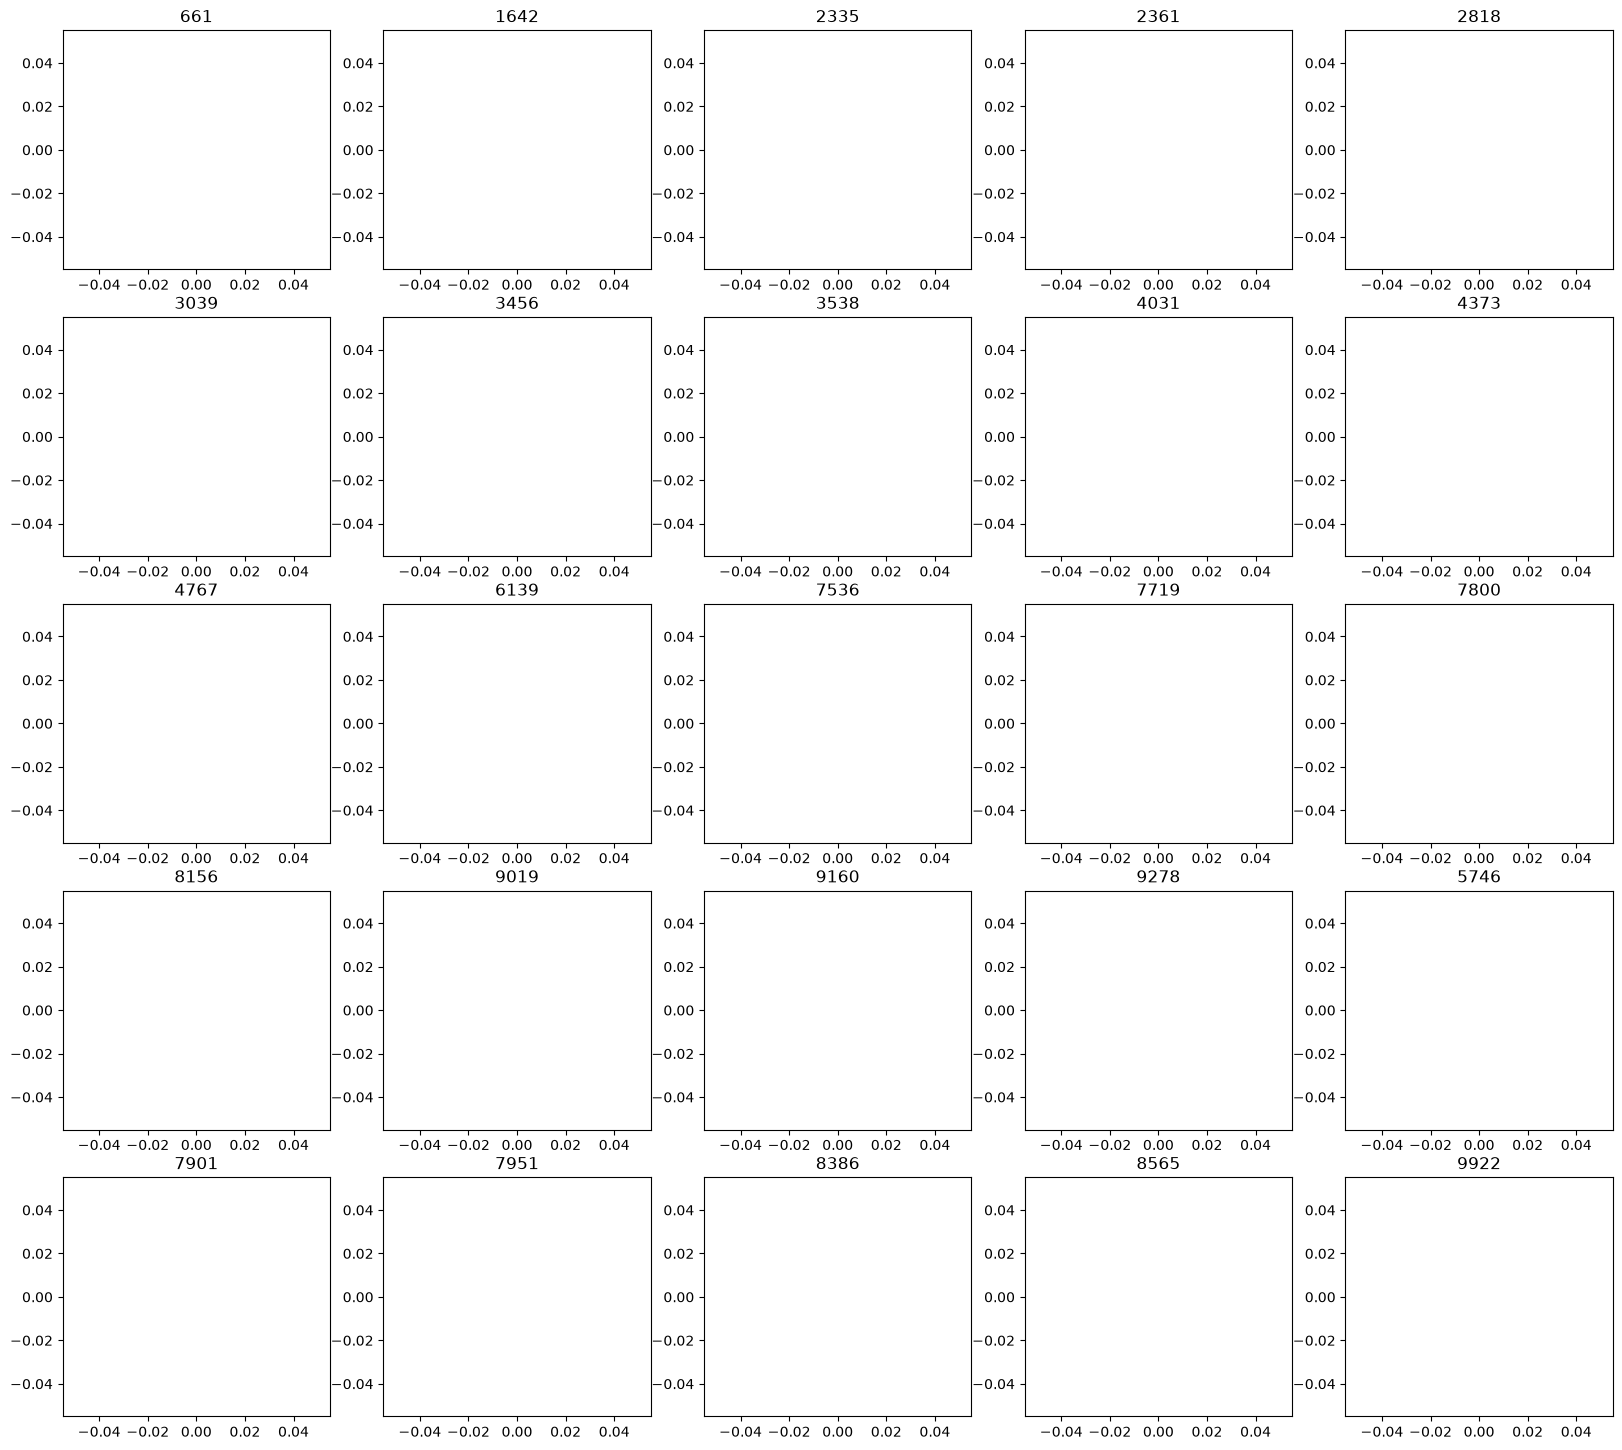

In [34]:
fig, axes = plt.subplots(nrows=5, ncols=5, figsize=(20,18))
axes = axes.flatten()
for i, ax in enumerate(axes):
    ax.plot(data[data['dataid']==PARTICIPANTS[i]].solar2)
    ax.set_title(str(PARTICIPANTS[i]))

There is no value recorded for 'solar2' for none of the houses. 

In [35]:
data = data.drop(columns=['solar2'])

### Which houses have Storage Units?

In [36]:
houses_with_battery = []
for id in PARTICIPANTS:
    row = austin_metadata[austin_metadata['dataid'] == id].iloc[0]
    if row['battery1']=='yes':
        houses_with_battery.append(id)


In [37]:
houses_with_battery

[]

None of the houses has any energy storage unit. 

In [38]:
data = data.drop(columns=['battery1'])

# Time Analysis

The date-time column, "local_15min", already contains timezone offsets.

In [39]:
data['timestamp'] = pd.to_datetime(data['local_15min'], errors='coerce', utc=True)

In [40]:
data = data.drop(columns=['local_15min'])

In [41]:
assert data['timestamp'].notna().all(), 'Missing timestamps.'

In [42]:
assert not data.duplicated(['dataid','timestamp']).any(), 'Duplicate household/timestamp rows: investigate source.'

In [43]:
for participant in PARTICIPANTS:
    df = data[data['dataid']==participant] 
    time_diff = df['timestamp'].sort_values().diff().dropna()
    is_equal = time_diff.eq(time_diff.iloc[0]).all()
    if not is_equal:
        print(f"The Sampling Intervals of the Data of House {participant} are not equal. The intervals are {time_diff.unique()}")


The Sampling Intervals of the Data of House 661 are not equal. The intervals are <TimedeltaArray>
['0 days 00:15:00', '0 days 01:15:00']
Length: 2, dtype: timedelta64[us]
The Sampling Intervals of the Data of House 1642 are not equal. The intervals are <TimedeltaArray>
['0 days 00:15:00', '0 days 03:15:00', '3 days 22:15:00', '0 days 01:15:00']
Length: 4, dtype: timedelta64[us]
The Sampling Intervals of the Data of House 2335 are not equal. The intervals are <TimedeltaArray>
['0 days 00:15:00', '5 days 22:15:00', '0 days 01:15:00']
Length: 3, dtype: timedelta64[us]
The Sampling Intervals of the Data of House 2361 are not equal. The intervals are <TimedeltaArray>
['0 days 00:15:00', '0 days 13:15:00', '0 days 01:15:00']
Length: 3, dtype: timedelta64[us]
The Sampling Intervals of the Data of House 2818 are not equal. The intervals are <TimedeltaArray>
['0 days 00:15:00', '0 days 14:15:00', '0 days 01:15:00']
Length: 3, dtype: timedelta64[us]
The Sampling Intervals of the Data of House 30

So, there are missing timestamps. The data needs to be reindexed. I will fix this issue for all participants in the last function. 

## What should be the start time?

In [44]:
Start_time = set()
for participant in PARTICIPANTS:
    df = data[data['dataid']==participant]
    Start_time.add(df['timestamp'].min())
Start_time

{Timestamp('2018-01-01 06:00:00+0000', tz='UTC'),
 Timestamp('2018-01-01 08:00:00+0000', tz='UTC')}

In [45]:
SATRT_TIME = pd.Timestamp('2018-01-01 08:00:00+0000')

## What should be the end time?

In [46]:
End_time = set()
for participant in PARTICIPANTS:
    df = data[data['dataid']==participant]
    End_time.add(df['timestamp'].max())
End_time

{Timestamp('2018-12-31 10:45:00+0000', tz='UTC'),
 Timestamp('2019-01-01 05:45:00+0000', tz='UTC')}

In [47]:
END_TIME = pd.Timestamp('2018-12-31 10:45:00+0000')

I will apply the generalization of START_TIME and END_TIME over the datasets of all participants in the last function. 

# Analyzing the Channels.

In the following, I will investigate what each column mean. Then I will categorize the loads to power-shiftable, time-shiftable, and non-shiftable loads.  

In [48]:
CHANNELS = data.columns.to_list()
CHANNELS = [channel for channel in CHANNELS if channel not in ['dataid', 'timestamp'] ] 
CHANNELS

['air1',
 'air2',
 'air3',
 'airwindowunit1',
 'aquarium1',
 'bathroom1',
 'bathroom2',
 'bedroom1',
 'bedroom2',
 'bedroom3',
 'bedroom4',
 'bedroom5',
 'car1',
 'car2',
 'circpump1',
 'clotheswasher1',
 'clotheswasher_dryg1',
 'diningroom1',
 'diningroom2',
 'dishwasher1',
 'disposal1',
 'drye1',
 'dryg1',
 'freezer1',
 'furnace1',
 'furnace2',
 'garage1',
 'garage2',
 'grid',
 'heater1',
 'heater2',
 'heater3',
 'housefan1',
 'icemaker1',
 'jacuzzi1',
 'kitchen1',
 'kitchen2',
 'kitchenapp1',
 'kitchenapp2',
 'lights_plugs1',
 'lights_plugs2',
 'lights_plugs3',
 'lights_plugs4',
 'lights_plugs5',
 'lights_plugs6',
 'livingroom1',
 'livingroom2',
 'microwave1',
 'office1',
 'outsidelights_plugs1',
 'outsidelights_plugs2',
 'oven1',
 'oven2',
 'pool1',
 'pool2',
 'poollight1',
 'poolpump1',
 'pump1',
 'range1',
 'refrigerator1',
 'refrigerator2',
 'security1',
 'sewerpump1',
 'shed1',
 'solar',
 'sprinkler1',
 'sumppump1',
 'utilityroom1',
 'venthood1',
 'waterheater1',
 'waterheater2

In [49]:
for channel in CHANNELS:
    if channel in metadata.columns:
        print(f"{channel}: {metadata.loc[0, channel]}")
    else:
        continue


air1: Air compressor circuit eGauge data present.
air2: Second air compressor circuit eGauge data present.
air3: Third air compressor circuit eGauge data present.
airwindowunit1: Window unit air conditioner circuit eGauge data present.
aquarium1: Aquarium circuit eGauge data present.
bathroom1: First bathroom circuit eGauge data present. This type of circuit includes only lights, fans, and wall outlets.
bathroom2: Second bathroom circuit eGauge data present. This type of circuit includes only lights, fans, and wall outlets.
bedroom1: First bedroom circuit eGauge data present. This type of circuit includes only lights, fans, and wall outlets.
bedroom2: Second bedroom circuit eGauge data present. This type of circuit includes only lights, fans, and wall outlets.
bedroom3: Third bedroom circuit eGauge data present. This type of circuit includes only lights, fans, and wall outlets.
bedroom4: Fourth bedroom circuit eGauge data present. This type of circuit includes only lights, fans, and wa

non-shiftable loads: 'air1', 'air2', 'air3', 'aquarium1', 'bathroom1', 'bathroom2', 'bedroom1', 'bedroom2', 'bedroom3', 'bedroom4', 'bedroom5', 'diningroom1', 'diningroom2', 'disposal1', 'freezer1', 'garage1', 'garage2', ''housefan1, 'icemaker1', 'jacuzzi1', 'kitchen1', 'kitchen2', 'kitchenapp1', 'kitchenapp1', 'lights_plugs1', 'lights_plugs2', 'lights_plugs3', 'lights_plugs4', 'lights_plugs5', 'lights_plugs6', 'livingroom1', 'livingroom2', 'microwave1', 'office1', 'outsidelights_plugs1', 'outsidelights_plugs2', 'oven1', 'oven2', 'pool1', 'pool2', 'poollight1', 'poolpump1', 'pump1', 'range1', 'refrigerator1', 'refrigerator1', 'security1', 'sewerpump1', 'shed1', 'sprinkler1', 'sumppump1', 'utilityroom1', 'venthood1', 'wellpump1'
* All non-shiftable loads will be summed up. 

power-shiftable loads: 'airwindowunit1', 'furnace1', 'furnace2', 'circpump1', 'heater1', 'heater2', 'heater3', 'car1', 'car2', 'waterheater1', 'waterheater2', 'winecooler1'
* Check which houses 'car2'.

time-shiftable loads: 'clotheswasher1', 'clotheswasher_dryg1', 'dishwasher1', 'drye1', 'dryg1'

* 'clotheswasher1' is labeled as 'WM'.
* 'clotheswasher_dryg1' is labeled as 'Dryer1'.
* 'dishwasher1' is labeled as 'DW'.
* 'drye1' is labeled as 'Dryer2'. 
* 'dryg1' is labeled as 'Dryer3'. 


'grid' and 'solar' columns are used as is. 

# Change and Save each House's Data based on the Analysis Results. 

In [50]:
def ToU(dt):
    if 4 <= dt.month <= 6: # Summer
        off_peak = 0.00493
        mid_peak = 0.05040
        on_peak = 0.09761
        if 0 <= dt.day_of_week <= 4: # Mon-Fri
            if 14 <= dt.hour < 20:
                    return on_peak
            elif 6 <= dt.hour < 14 or 20 <= dt.hour < 22:
                    return mid_peak
            else:
                    return off_peak
        else: # Sat-Sun
              if 6 <= dt.hour < 22:
                    return mid_peak
              else:
                    return off_peak
    else: # Non-Summer
        off_peak = 0.00924
        mid_peak = 0.01201
        on_peak = 0.09761
        if 6 <= dt.hour < 22:
            return mid_peak
        else:
            return off_peak

def process_participant(participant_id):
    # household metadata
    participant_type = customer_type[participant_id]
    
    non_shiftable_loads_list = ['air1', 'air2', 'air3', 'aquarium1', 'bathroom1', 'bathroom2', 'bedroom1', 'bedroom2', 'bedroom3', 'bedroom4', 'bedroom5', 'diningroom1', 'diningroom2', 'disposal1', 'freezer1', 'garage1', 'garage2', 'housefan1', 'icemaker1', 'jacuzzi1', 'kitchen1', 'kitchen2', 'kitchenapp1', 'kitchenapp2', 'lights_plugs1', 'lights_plugs2', 'lights_plugs3', 'lights_plugs4', 'lights_plugs5', 'lights_plugs6', 'livingroom1', 'livingroom2', 'microwave1', 'office1', 'outsidelights_plugs1', 'outsidelights_plugs2', 'oven1', 'oven2', 'pool1', 'pool2', 'poollight1', 'poolpump1', 'pump1', 'range1', 'refrigerator1', 'refrigerator2', 'security1', 'sewerpump1', 'shed1', 'sprinkler1', 'sumppump1', 'utilityroom1', 'venthood1', 'wellpump1']
    power_shiftable_loads_list = ['airwindowunit1', 'furnace1', 'furnace2', 'circpump1', 'heater1', 'heater2', 'heater3', 'car1', 'car2', 'waterheater1', 'waterheater2', 'winecooler1']
    time_shiftable_loads_list = ['clotheswasher1', 'clotheswasher_dryg1', 'dishwasher1', 'drye1', 'dryg1']
    
    df = data.loc[data["dataid"].eq(participant_id)].copy()

    # Determine which loads exist
    detected_power_shiftable = [col for col in power_shiftable_loads_list if col in df.columns and df[col].notna().any()]
    detected_time_shiftable = [col for col in time_shiftable_loads_list if col in df.columns and df[col].notna().any()]
    
    metadata_out = {
        'participant_type': participant_type,
        'power_shiftable_loads': detected_power_shiftable,
        'time_shiftable_loads': detected_time_shiftable
    }

    # time analysis requirements
    df["timestamp"] = pd.to_datetime(df["timestamp"])
    df = df.sort_values("timestamp").set_index("timestamp")
    
    ## start time and end time 
    global END_TIME
    END_TIME_local = END_TIME + pd.Timedelta(minutes=15)
    df = df[SATRT_TIME:END_TIME_local]

    ## reindexing 
    regular_index = pd.date_range(
        start=df.index.min(),
        end=df.index.max(),
        freq="15min",
        tz=df.index.tz,
    )
    df = df.reindex(regular_index)
    df.index.name = "datetime"

    # time-related features
    cal = USFederalHolidayCalendar()
    holidays = cal.holidays(start=df.index.min(), end=df.index.max())
    df['Is_a_holiday'] = df.index.isin(holidays).astype(int)
    df['day_of_week'] = df.index.day_of_week
    df['month'] = df.index.month
    total_minutes = df.index.hour * 60 + df.index.minute
    df['sine_of_time'] = np.sin(2 * np.pi * total_minutes / 1440)
    df['cosine_of_time'] = np.cos(2 * np.pi * total_minutes / 1440)
    
    # Calculate nonshiftable_loads sum
    detected_non_shiftable = [col for col in non_shiftable_loads_list if col in df.columns and df[col].notna().any()]
    if detected_non_shiftable:
        df['nonshiftable_loads'] = df[detected_non_shiftable].sum(axis=1)
    else:
        df['nonshiftable_loads'] = 0.0
        
    
    # ToU calculation
    df['ToU'] = df.index.map(ToU)
    
    cols_to_keep = ['grid', 'solar']
    cols_to_keep.append('nonshiftable_loads')
    cols_to_keep.extend(detected_power_shiftable)
    cols_to_keep.extend(detected_time_shiftable)
    cols_to_keep.extend(['sine_of_time', 'cosine_of_time', 'day_of_week', 'month', 'Is_a_holiday', 'ToU'])
            
    df_out = df[[c for c in cols_to_keep if c in df.columns]]

    # replace NaNs with 0s.
    df_out = df_out.fillna(0)
    
    return metadata_out, df_out


In the following, the function is used to save the datasets of two prosumers and two consumers. 

In [51]:
for consumer in CONSUMERS[0:2]:
    metadata_out, df_out = process_participant(participant_id=consumer)
    df_out.to_csv(OUTPUT_DIR/f'energy_data_consumer_{consumer}.csv')
    with open(OUTPUT_DIR/f'energy_data_consumer_{consumer}.json', 'w') as JSON_file:
        json.dump(metadata_out, JSON_file, indent=4)

In [52]:
for prosumer in PROSUMERS[0:2]:
    metadata_out, df_out = process_participant(participant_id=prosumer)
    df_out.to_csv(OUTPUT_DIR/f'energy_data_prosumer_{prosumer}.csv')
    with open(OUTPUT_DIR/f'energy_data_prosumer_{prosumer}.json', 'w') as JSON_file:
        json.dump(metadata_out, JSON_file, indent=4)